# gfbr_mem: constrained MEM (the GFBR solver step in Python)

Per curve, solve: maximize the entropy `-sum(a_i ln a_i)` subject to `a_i >= eps`, `sum(a_i) = 1`, and `sum((K a - g1)^2) <= C` (Euclidean distance, no sigma weighting). Solver: IPOPT through CasADi, SciPy SLSQP as a cross-check.

**Input.** The trimmed curves from `gfbr_data.npz`. For one curve with indices `ic`, `iz` the MEM system uses

- rows `K[0..ic]` with the noisy g1 values as targets (the data above g1 = 0.05), and
- rows `K[iz..iz+12]` with target exactly 0 (13 zero points, taken after g1 has fallen below 1e-4).

**Constraint level.** `C = 1.02 * Cb`, where `Cb` is the feasibility boundary: the smallest distance reachable by any `a` on the simplex. Below `Cb` the problem has no solution, so `Cb` is computed exactly (non-negative least squares) for every curve.

**Zero rows and `iz`.** The library stores the exact `iz` (closest point to g1 = 1e-4 on the clean curve). For single peaks that is the same point a single-exponential fit gives. For bimodals the fit puts it earlier, so for them the notebook takes `iz` from a single-exponential fit to the noisy curve, as `clipG2toG1` does (`iz_from_fit`). `ic` always comes from the library.

In [1]:
import os
import numpy as np
import casadi as ca
from scipy.optimize import minimize, nnls
import matplotlib.pyplot as plt

data = np.load("gfbr_data.npz")
R, tau, K, sigma = data["R"], data["tau"], data["K"], float(data["sigma"])
nzero = int(data["nzero"])
N, M = K.shape
EPS = 1e-12
print(N, M, sigma, "nzero =", nzero)

100 150 0.006 nzero = 13


## Functions
- `mem_system`: picks the K rows and targets for one trimmed curve (kept points + `nzero` zeros).
- `cb_exact`: the feasibility boundary `Cb`.
- `dls_mem_c`: the IPOPT solve. `bound_relax_factor = 0` stops IPOPT from stepping slightly below zero, where `log(a + EPS)` would be NaN.
- `dls_mem_c_slsqp`: the same problem in SciPy, used only as a cross-check.
- `peak_stats`: mass, mean radius and relative width of the part of a distribution on each side of `split`.
- `iz_from_fit`: `iz` from a single-exponential fit `exp(-a*tau)` to the full noisy curve: the first lag time after g1 = 1e-4 on the fit.
- `left_cv`: your `memPeakHalfInterp`: peak = maximum of `a_i`, left half-maximum by linear interpolation, `cv = (R_peak - R_half)/(1.177 R_peak)`.

In [2]:
def mem_system(g1_trim, ic, iz, nzero=nzero):
    # rows of K and targets for one trimmed curve: points 0..ic with their data, then nzero zero-target rows starting at iz
    zeros = np.arange(iz, min(iz + nzero, N))          # for the slowest curves iz + nzero can run past the grid: take what exists
    idx = np.r_[np.arange(ic + 1), zeros]
    target = np.r_[g1_trim[:ic + 1], np.zeros(len(zeros))]
    return K[idx], target

def cb_exact(K_, g1_):
    # feasibility boundary Cb: smallest ||K a - g1||^2 over the simplex (NNLS with a heavily weighted sum(a) = 1 row)
    A = np.vstack([K_, 1e3*np.ones((1, K_.shape[1]))]); b = np.r_[g1_, 1e3]
    a, _ = nnls(A, b, maxiter=50000)
    return np.sum((K_@a - g1_)**2)

def dls_mem_c(K_, g1_, C, tol=1e-5, max_iter=500):
    # IPOPT, as in dlsMEMc
    M_ = K_.shape[1]
    a = ca.SX.sym("a", M_)
    neg_entropy = ca.sum1(a*ca.log(a + EPS))                  # minimizing this = maximizing the entropy
    r = ca.mtimes(ca.DM(K_), a) - ca.DM(g1_)
    cons = ca.vertcat(ca.sum1(a) - 1, ca.dot(r, r) - C)       # sum(a) = 1 ;  ||K a - g1||^2 <= C
    solver = ca.nlpsol("s", "ipopt", {"x": a, "f": neg_entropy, "g": cons},
                       {"ipopt.tol": tol, "ipopt.max_iter": max_iter, "ipopt.print_level": 0, "print_time": 0,
                        "ipopt.bound_relax_factor": 0})
    sol = solver(x0=np.full(M_, 1.0/M_), lbx=EPS, ubx=1.0, lbg=[0, -ca.inf], ubg=[0, 0])
    st = solver.stats()
    return np.array(sol["x"]).ravel(), st["return_status"], st["iter_count"]

def dls_mem_c_slsqp(K_, g1_, C):
    # cross-check with SciPy SLSQP
    M_ = K_.shape[1]
    f  = lambda a: np.sum(a*np.log(a + EPS))
    gf = lambda a: np.log(a + EPS) + a/(a + EPS)
    cons = [{'type': 'ineq', 'fun': lambda a: C - np.sum((K_@a - g1_)**2), 'jac': lambda a: -2*K_.T@(K_@a - g1_)},
            {'type': 'eq',   'fun': lambda a: a.sum() - 1,                 'jac': lambda a: np.ones(M_)}]
    res = minimize(f, np.full(M_, 1.0/M_), jac=gf, constraints=cons, bounds=[(EPS, 1.0)]*M_,
                   method='SLSQP', options={'maxiter': 300, 'ftol': 1e-10})
    return res.x

def mem_solve(g1_trim, ic, iz, factor=1.02):
    # the full per-curve pipeline: build the system, compute Cb, solve at C = factor * Cb
    K_, t_ = mem_system(g1_trim, ic, iz)
    Cb = cb_exact(K_, t_)
    a, status, it = dls_mem_c(K_, t_, factor*Cb)
    return a, dict(Cb=Cb, status=status, iters=it, n_rows=len(t_), K_=K_, t_=t_, C=factor*Cb)

def peak_stats(R, p, split):
    # for each side of `split`: mass, mean radius (nm) and cv = std(R)/mean(R) of the distribution on that side
    out = []
    for sel in [R < split, R >= split]:
        w = p[sel]/p[sel].sum(); mean = (w*R[sel]).sum(); std = np.sqrt((w*(R[sel] - mean)**2).sum())
        out.append((p[sel].sum(), mean*1e9, std/mean))
    return out

def iz_from_fit(g1_full, g1_zero=1e-4):
    # single-exponential fit exp(-a*tau) to the FULL noisy curve; iz = first lag time at or after the fit's g1_zero crossing
    from scipy.optimize import curve_fit
    (a,), _ = curve_fit(lambda t, a: np.exp(-a*t), tau, g1_full, p0=[1.0/tau[np.argmin(np.abs(g1_full - 0.37))]])
    return int(np.where(tau >= -np.log(g1_zero)/a)[0][0])

def left_cv(R, p, lo=0.0, hi=np.inf, level=0.5, thr_frac=0.01):
    # one peak = bins with lo <= R < hi; returns (peak radius, left-side cv)
    sel = np.where((R >= lo) & (R < hi))[0]; ip = sel[np.argmax(p[sel])]
    left = np.arange(sel[0], ip + 1); left = left[p[left] > thr_frac*p[ip]]
    for j in range(len(left) - 1):
        y1, y2 = p[left[j]], p[left[j + 1]]
        if y1 <= level*p[ip] <= y2:
            r_half = R[left[j]] + (level*p[ip] - y1)*(R[left[j + 1]] - R[left[j]])/(y2 - y1)
            return R[ip], (R[ip] - r_half)/(1.177*R[ip])
    return R[ip], np.nan

## Two fits from the library
One unimodal curve (random from the validation set) and one bimodal curve (random noise draw of the 4 + 16 nm bimodal). Each curve gets its own constraint level `C = factor * Cb`: set `factor_uni` and `factor_bi` separately. Change `seed` to pick other curves.

- unimodal: `ic` and `iz` from the library.
- bimodal: `ic` from the library, `iz` from the single-exponential fit (`iz_from_fit`).

In [13]:
seed       = 0
factor_uni = 1.005      # C = factor * Cb for the unimodal curve
factor_bi  = 1.006      # C = factor * Cb for the bimodal curve

rng = np.random.default_rng(seed)
ku = int(rng.integers(len(data["d_val"])))      # random validation curve
kb = int(rng.integers(len(data["d_bi"])))       # random noise draw of the bimodal

# --- unimodal: library indices ---
d_u = data["d_val"][ku]
a_u, inf_u = mem_solve(data["g1_trim_val"][ku], data["ic_val"][ku], data["iz_val"][ku], factor=factor_uni)

# --- bimodal: ic from the library, iz from the single-exponential fit ---
d_b  = data["d_bi_single"]
iz_b = iz_from_fit(data["g1_full_bi"][kb])
a_b, inf_b = mem_solve(data["g1_trim_bi"][kb], data["ic_bi"][kb], iz_b, factor=factor_bi)

for name, inf, f in [("unimodal", inf_u, factor_uni), ("bimodal", inf_b, factor_bi)]:
    print(f"{name}: {inf['status']}, {inf['iters']} iters, rows = {inf['n_rows']}, Cb = {inf['Cb']:.3e}, C = {f}*Cb = {inf['C']:.3e}")
print(f"unimodal: val #{ku}, R0 = {data['R0_val'][ku]*1e9:.1f} nm, cv = {data['cv_val'][ku]:.3f}, ic/iz = {data['ic_val'][ku]}/{data['iz_val'][ku]}")
print(f"bimodal : noise draw #{kb}, ic/iz = {data['ic_bi'][kb]}/{iz_b}  (library iz = {data['iz_bi'][kb]})")

# peak position and left-cv: truth vs MEM
split = np.sqrt(float(data["bi_R1"])*float(data["bi_R2"]))
print("\nunimodal  true: mode %.1f nm, left-cv %.3f | MEM: mode %.1f nm, left-cv %.3f" % (*[x*(1e9 if i == 0 else 1) for i, x in enumerate(left_cv(R, d_u))], *[x*(1e9 if i == 0 else 1) for i, x in enumerate(left_cv(R, a_u))]))
for lab, lo, hi in [("peak 1", 0.0, split), ("peak 2", split, np.inf)]:
    (rt, ct), (rm, cm) = left_cv(R, d_b, lo, hi), left_cv(R, a_b, lo, hi)
    mt, mm = d_b[(R >= lo) & (R < hi)].sum(), a_b[(R >= lo) & (R < hi)].sum()
    print(f"bimodal {lab}: true mass {mt:.2f}, mode {rt*1e9:.1f} nm, left-cv {ct:.3f} | MEM mass {mm:.2f}, mode {rm*1e9:.1f} nm, left-cv {cm:.3f}")

unimodal: Solve_Succeeded, 38 iters, rows = 60, Cb = 1.205e-03, C = 1.005*Cb = 1.211e-03
bimodal: Solve_Succeeded, 37 iters, rows = 68, Cb = 2.055e-03, C = 1.006*Cb = 2.067e-03
unimodal: val #871, R0 = 3.4 nm, cv = 0.096, ic/iz = 46/55
bimodal : noise draw #63, ic/iz = 54/59  (library iz = 65)

unimodal  true: mode 3.4 nm, left-cv 0.092 | MEM: mode 3.4 nm, left-cv 0.107
bimodal peak 1: true mass 0.70, mode 4.0 nm, left-cv 0.129 | MEM mass 0.72, mode 4.1 nm, left-cv 0.143
bimodal peak 2: true mass 0.30, mode 15.7 nm, left-cv 0.122 | MEM mass 0.28, mode 17.1 nm, left-cv 0.116


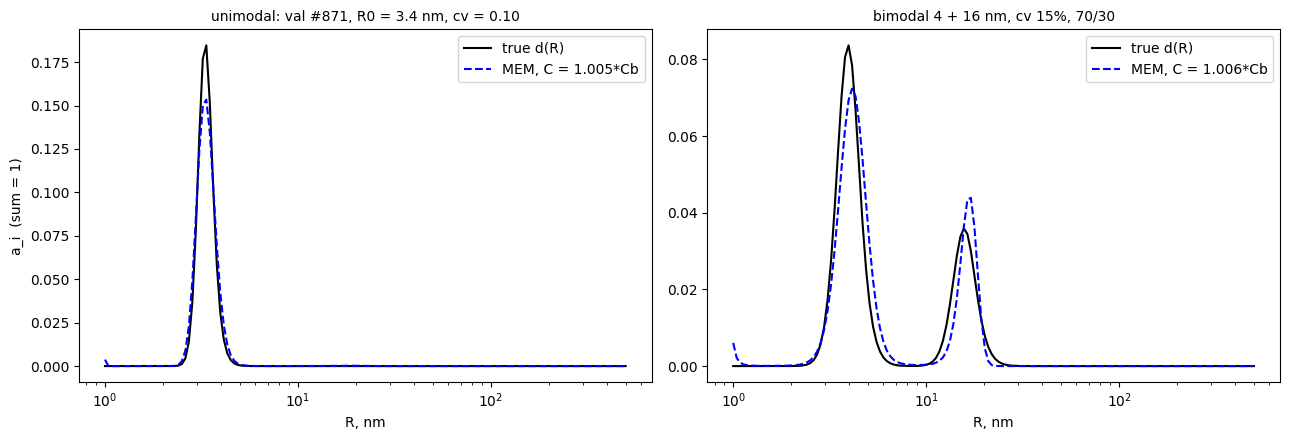

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].semilogx(R*1e9, d_u, 'k-', label='true d(R)'); axes[0].semilogx(R*1e9, a_u, 'b--', label=f'MEM, C = {factor_uni}*Cb')
axes[0].set_title(f"unimodal: val #{ku}, R0 = {data['R0_val'][ku]*1e9:.1f} nm, cv = {data['cv_val'][ku]:.2f}", fontsize=10)
axes[1].semilogx(R*1e9, d_b, 'k-', label='true d(R)'); axes[1].semilogx(R*1e9, a_b, 'b--', label=f'MEM, C = {factor_bi}*Cb')
axes[1].set_title("bimodal 4 + 16 nm, cv 15%, 70/30", fontsize=10)
for ax in axes: ax.set_xlabel('R, nm'); ax.legend()
axes[0].set_ylabel('a_i  (sum = 1)')
plt.tight_layout(); os.makedirs("figures", exist_ok=True); plt.savefig('figures/gfbr_mem_fits.png', dpi=130); plt.show()